In [14]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
SPY = yf.download("SPY", start="2015-01-01",interval="1d", auto_adjust=True)

[*********************100%***********************]  1 of 1 completed


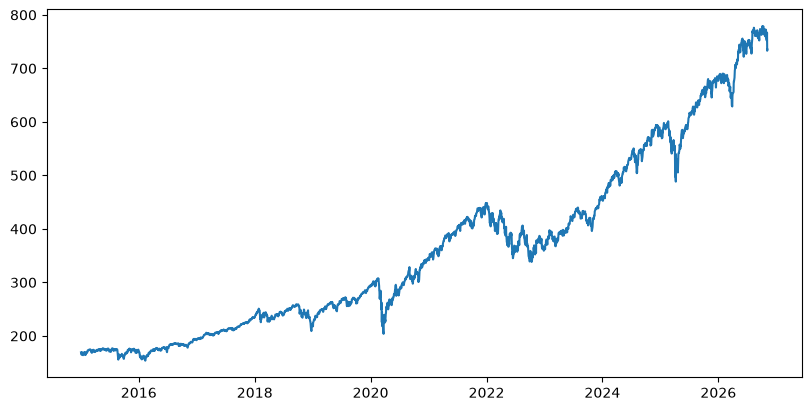

In [21]:
fg, ax = plt.subplots(figsize=(8,4), layout='constrained')
ax.plot(SPY['Close'])

#### Objectif -> Est ce que un mois de hausse augmente le pourcentage de chance d'avoir le mois suivant en hausse ou est ce que c'est du 50/50 ? 

In [28]:
# Verifier la qualité des closes
print(SPY.index.is_monotonic_increasing) # Ici on regarde si les dates sont bien en ordre chornologique 
print(SPY.index.has_duplicates) # Y'a des doublons ? 
print(SPY['Close'].isna().sum()) # Y'a des valeurs Nan ?

True
False
Ticker
SPY    0
dtype: int64


In [54]:
SPY_MONTLHY_CLOSE = SPY['Close'].loc[:"2026-10-31"].resample("ME").last()
RENDEMENT_MONTHLY = SPY_MONTLHY_CLOSE / SPY_MONTLHY_CLOSE.shift(1) - 1
RENDEMENT_MONTHLY

Ticker,SPY
Date,
2015-01-31,NaN
2015-02-28,0.056205
2015-03-31,-0.015706
2015-04-30,0.009834
2015-05-31,0.012856
...,...
2026-06-30,-0.010293
2026-07-31,0.000348
2026-08-31,0.026799


In [55]:
RENDEMENT_MONTHLY_TWO = RENDEMENT_MONTHLY.copy()
RENDEMENT_MONTHLY_TWO['Rendement_suivant'] = RENDEMENT_MONTHLY.shift(-1)
RENDEMENT_MONTHLY_TWO

Ticker,SPY,Rendement_suivant
Date,,
2015-01-31,NaN,0.056205
2015-02-28,0.056205,-0.015706
2015-03-31,-0.015706,0.009834
2015-04-30,0.009834,0.012856
2015-05-31,0.012856,-0.020312
...,...,...
2026-06-30,-0.010293,0.000348
2026-07-31,0.000348,0.026799
2026-08-31,0.026799,-0.003293


In [90]:
MONTH_POSITIVE=(RENDEMENT_MONTHLY_TWO['Rendement_suivant']>0).sum()
FREQUENCE_MONTH_POSITIVE = MONTH_POSITIVE / RENDEMENT_MONTHLY_TWO.shape[0]
print(f"Frequence d'un mois positif {FREQUENCE_MONTH_POSITIVE}")

Frequence d'un mois positif 0.6830985915492958


In [83]:
RENDEMENT_MONTHLY_TWO.dropna()

Ticker,SPY,Rendement_suivant
Date,,
2015-02-28,0.056205,-0.015706
2015-03-31,-0.015706,0.009834
2015-04-30,0.009834,0.012856
2015-05-31,0.012856,-0.020312
2015-06-30,-0.020312,0.022590
...,...,...
2026-05-31,0.052626,-0.010293
2026-06-30,-0.010293,0.000348
2026-07-31,0.000348,0.026799


In [84]:
MONTH_POSITIVE_CURRENT=(RENDEMENT_MONTHLY_TWO['SPY']>0)
MONTH_POSITIVE_NEXT=(RENDEMENT_MONTHLY_TWO['Rendement_suivant']>0)
MONTH_POSITIVE_EXCLUSIF=((MONTH_POSITIVE_NEXT&MONTH_POSITIVE_CURRENT)).sum()
FREQUENCE = MONTH_POSITIVE_EXCLUSIF / MONTH_POSITIVE_CURRENT.sum()

In [ ]:
FREQUENCE


# J'ai l'impression que on peut conclure que quand un mois termine en positif on a 70% de chance que le suivant soit positif aussi 

np.float64(0.7010309278350515)

<BarContainer object of 2 artists>

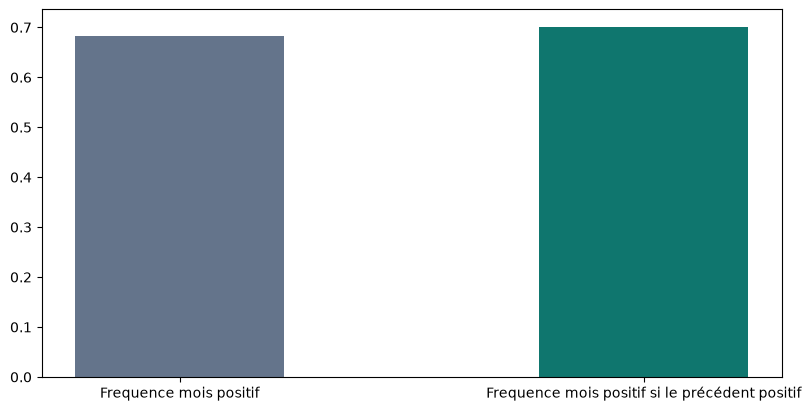

In [96]:
fg, ax = plt.subplots(figsize=(8,4),layout="constrained")
ax.bar(["Frequence mois positif","Frequence mois positif si le précédent positif"],[FREQUENCE_MONTH_POSITIVE,FREQUENCE],width=0.45,color=["#64748B", "#0F766E"])
